# CIFAR-10 Image Classification with a CNN (TensorFlow / Keras)

## Overview

This notebook builds and trains a **Convolutional Neural Network (CNN)** to classify images from the **CIFAR-10** dataset using TensorFlow and Keras.

CIFAR-10 contains **60,000 color images** of size **32x32 pixels** (RGB), split into **50,000 training** and **10,000 test** images. The images are evenly distributed across **10 classes**

The images are small and low resolution, and several classes look alike (cat vs. dog, automobile vs. truck), which makes CIFAR-10 a good benchmark for testing how well a CNN extracts visual features.

## Workflow

1. **Imports and setup**: libraries and reproducibility seed
2. **Load the data**: download CIFAR-10 and inspect shapes
3. **Data exploration**: sample images, class distribution per-class examples
4. **Preprocessing**: scale pixel values from `[0, 255]` to `[0, 1]`
5. **Build the CNN**: 3 blocks of Conv, BatchNorm, Dropout and Pooling, then the dense classifier
6. **Compile**: Adam optimizer, sparse categorical cross-entropy loss, accuracy metric
7. **Train**: with early stopping and learning-rate reduction on a validation split
8. **Training history**: accuracy and loss curves plotted side by side
9. **Evaluation**: test accuracy and a full classification report (precision, recall, F1-score per class)
10. **Inference**: predict a random test image and compare the actual and predicted labels

## Goals

- Understand the data before modeling it
- Build a CNN that generalizes well, using BatchNorm and Dropout to limit overfitting
- Evaluate beyond overall accuracy by looking at per-class performance
- Check individual predictions on unseen images

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.datasets import cifar10
from sklearn.metrics import classification_report

print("TensorFlow version:", tf.__version__)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.17.0


## 2. Load the data

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Labels come as shape (N, 1) -> flatten to (N,)
y_train = y_train.flatten()
y_test = y_test.flatten()

print("x_train:", x_train.shape, x_train.dtype)
print("y_train:", y_train.shape)
print("x_test: ", x_test.shape)
print("y_test: ", y_test.shape)

x_train: (50000, 32, 32, 3) uint8
y_train: (50000,)
x_test:  (10000, 32, 32, 3)
y_test:  (10000,)


## 3. Quick data exploration

### 3.1 Sample images

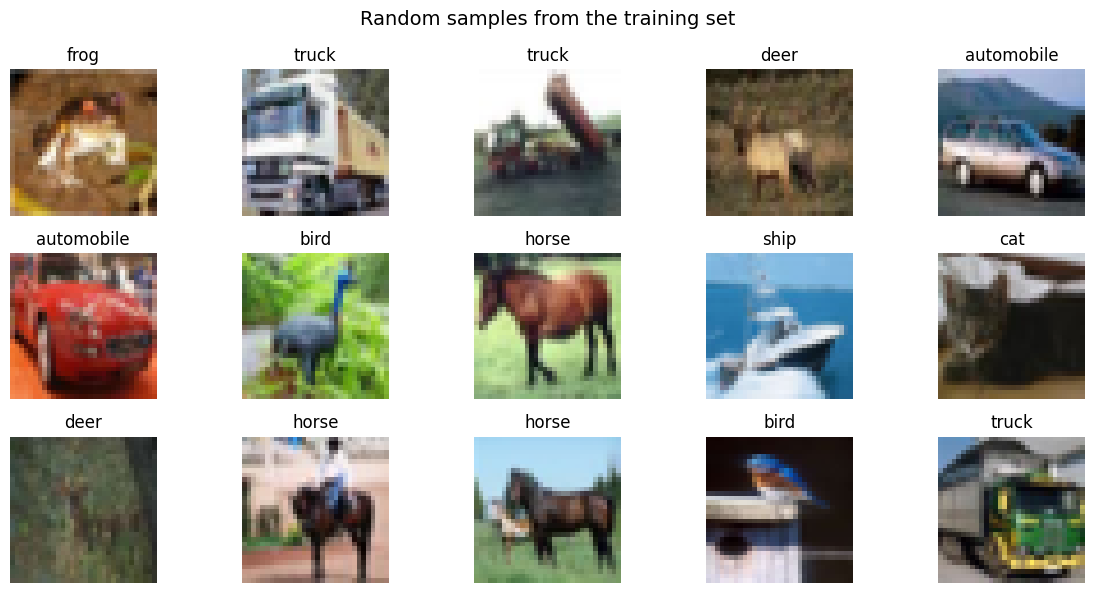

In [3]:
plt.figure(figsize=(12, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.suptitle("Random samples from the training set", fontsize=14)
plt.tight_layout()
plt.show()

### 3.2 Class distribution

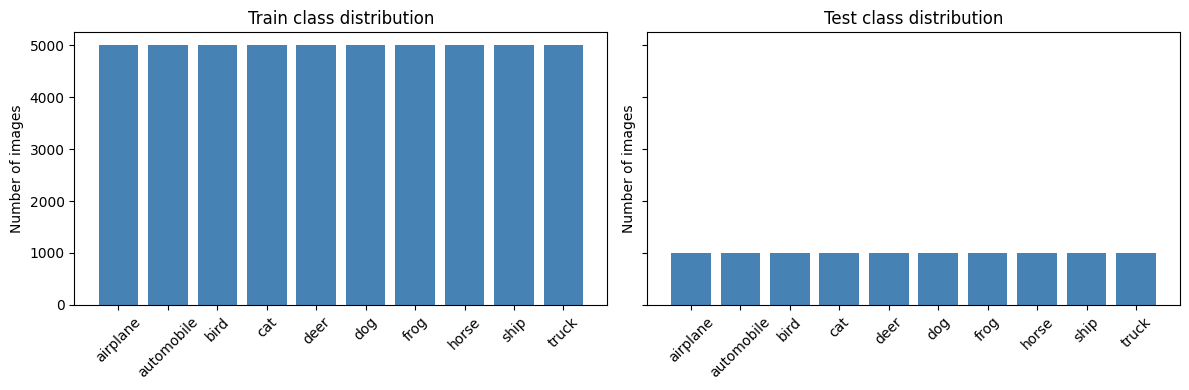

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, labels, title in zip(axes, [y_train, y_test], ["Train", "Test"]):
    counts = np.bincount(labels, minlength=10)
    ax.bar(class_names, counts, color='steelblue')
    ax.set_title(f"{title} class distribution")
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel("Number of images")

plt.tight_layout()
plt.show()

### 3.3 One example per class

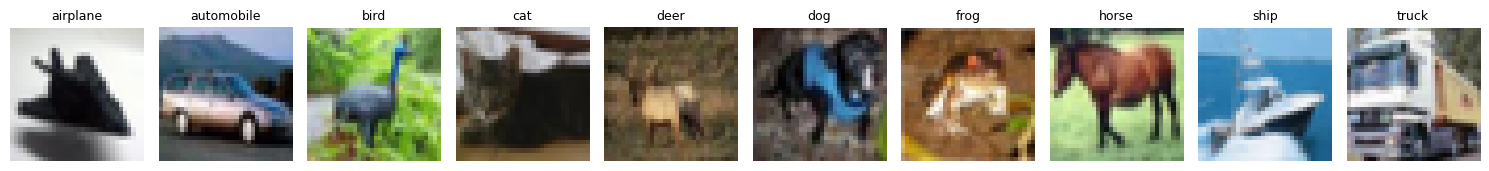

In [5]:
plt.figure(figsize=(15, 3))
for class_id, name in enumerate(class_names):
    idx = np.where(y_train == class_id)[0][0]
    plt.subplot(1, 10, class_id + 1)
    plt.imshow(x_train[idx])
    plt.title(name, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Preprocessing

Scale pixels to [0, 1]. Labels stay as integers, so we use `sparse_categorical_crossentropy`.

In [6]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("New pixel range:", x_train.min(), "-", x_train.max())

New pixel range: 0.0 - 1.0


## 5. Build the CNN

The model is a `Sequential` stack of layers, meaning each layer's output feeds directly into the next layer's input. As with any CNN, the key thing to track is how the tensor's shape changes at every layer: `(height, width, channels)`. Each layer's output shape must match the next layer's expected input shape.

Every convolutional block follows the same pattern: **Conv → BatchNorm → Dropout → Pooling**. The block is repeated three times, each time with more filters, so the network learns increasingly complex features while the spatial size shrinks.

### Input

`Input(shape=(32, 32, 3))` declares that every image entering the network has shape `(32, 32, 3)`: 32x32 pixels, 3 channels (RGB).

### Conv Block 1

- `Conv2D(32, (3, 3), padding='same', activation='relu')`: takes the **3 input channels** of the image and produces **32 output channels** (32 learned feature maps), using `3x3` filters. `padding='same'` keeps the spatial size unchanged, and the ReLU activation is applied directly inside the layer, so the output shape becomes `(32, 32, 32)`.
- `BatchNormalization()`: normalizes the activations of each of the 32 channels across the batch, which stabilizes and speeds up training. The shape stays `(32, 32, 32)`.
- `Dropout(0.2)`: randomly zeroes 20% of the values during training for light regularization; shape stays `(32, 32, 32)`.
- `MaxPooling2D((2, 2))`: keeps the **32 channels** from the previous layers but halves the height and width, turning `(32, 32, 32)` into `(16, 16, 32)`.

### Conv Block 2

- `Conv2D(64, (3, 3), padding='same', activation='relu')`: this is where the input/output relationship between blocks matters. This layer's **input channels (32)** must exactly match the **output channels (32)** produced by Conv Block 1. It then produces **64 output channels**. With `padding='same'` the spatial size is preserved, so the shape becomes `(16, 16, 64)`.
- `BatchNormalization()`: normalizes each of the 64 channels; shape unchanged, `(16, 16, 64)`.
- `Dropout(0.3)`: slightly stronger regularization; shape stays `(16, 16, 64)`.
- `MaxPooling2D((2, 2))`: halves the spatial size again, turning `(16, 16, 64)` into `(8, 8, 64)`.

### Conv Block 3

- `Conv2D(128, (3, 3), padding='same', activation='relu')`: its **input channels (64)** must match the **output channels (64)** of Conv Block 2. It produces **128 output channels**, and the shape becomes `(8, 8, 128)`.
- `BatchNormalization()`: normalizes each of the 128 channels; shape unchanged, `(8, 8, 128)`.
- `Dropout(0.4)`: the strongest dropout among the convolutional blocks, since this block has the most parameters and is the most prone to overfitting; shape stays `(8, 8, 128)`.
- `MaxPooling2D((2, 2))`: halves the spatial size, turning `(8, 8, 128)` into `(4, 4, 128)`.

After the three convolutional blocks, each image has become a tensor of shape `(4, 4, 128)`: 128 feature maps, each 4x4 pixels.

### Dense Classifier

- `Flatten()`: reshapes each `(4, 4, 128)` tensor into a single 1-dimensional vector of length `4 * 4 * 128 = 2048`.
- `Dense(128, activation='relu')`: the **input size (2048)** must exactly match the flattened vector length produced above. It maps those 2048 values down to **128 output nodes**.
- `BatchNormalization()`: normalizes the 128 values; shape unchanged.
- `Dropout(0.5)`: randomly zeroes 50% of the 128 values during training, a stronger regularization typical right before the final output layer.
- `Dense(10, activation='softmax')`: the **input size (128)** matches the output of the previous layer, and it produces **10 output values**, one per CIFAR-10 class (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck). The `softmax` activation turns these into a probability distribution that sums to 1.

`BatchNormalization` and `Dropout` layers never change the tensor's shape, which is why they do not appear in the table. In this model, every convolutional and hidden dense layer is followed by a `BatchNormalization` layer and a `Dropout` layer, and the dropout rate increases with depth (0.2, 0.3, 0.4, then 0.5) as the layers get larger and more prone to overfitting.

In [7]:
def conv_block(filters, dropout_rate):
    return [
        layers.Conv2D(filters, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),
        layers.MaxPooling2D((2, 2)),
    ]

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    *conv_block(32, 0.2),    # Block 1: 32x32 -> 16x16
    *conv_block(64, 0.3),    # Block 2: 16x16 -> 8x8
    *conv_block(128, 0.4),   # Block 3: 8x8   -> 4x4

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax'),
], name="cifar10_cnn")

model.summary()

Model: "cifar10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 358,218 (1.37 MB)

 Trainable params: 357,514 (1.36 MB)

 Non-trainable params: 704 (2.75 KB)

## 6. Compile (Adam)

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 7. Train

In [9]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1
)

history = model.fit(
    x_train, y_train,
    epochs=40,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 54s 67ms/step - accuracy: 0.3672 - loss: 1.9438 - val_accuracy: 0.4674 - val_loss: 1.5922 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 46s 65ms/step - accuracy: 0.5867 - loss: 1.1710 - val_accuracy: 0.5578 - val_loss: 1.2796 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 46s 66ms/step - accuracy: 0.6495 - loss: 1.0015 - val_accuracy: 0.6252 - val_loss: 1.0728 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 49s 70ms/step - accuracy: 0.6834 - loss: 0.9114 - val_accuracy: 0.6902 - val_loss: 0.8758 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 46s 66ms/step - accuracy: 0.7096 - loss: 0.8391 - val_accuracy: 0.6430 - val_loss: 1.0738 - learning_rate: 0.0010
Epoch 6/40
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.7280 - loss: 0.7846
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
704/704 ━━━━━━━━━━━━━━━━━━━━ 45s 63ms/step - accuracy: 0.7280 - los

## 8. Training history: accuracy and loss side by side

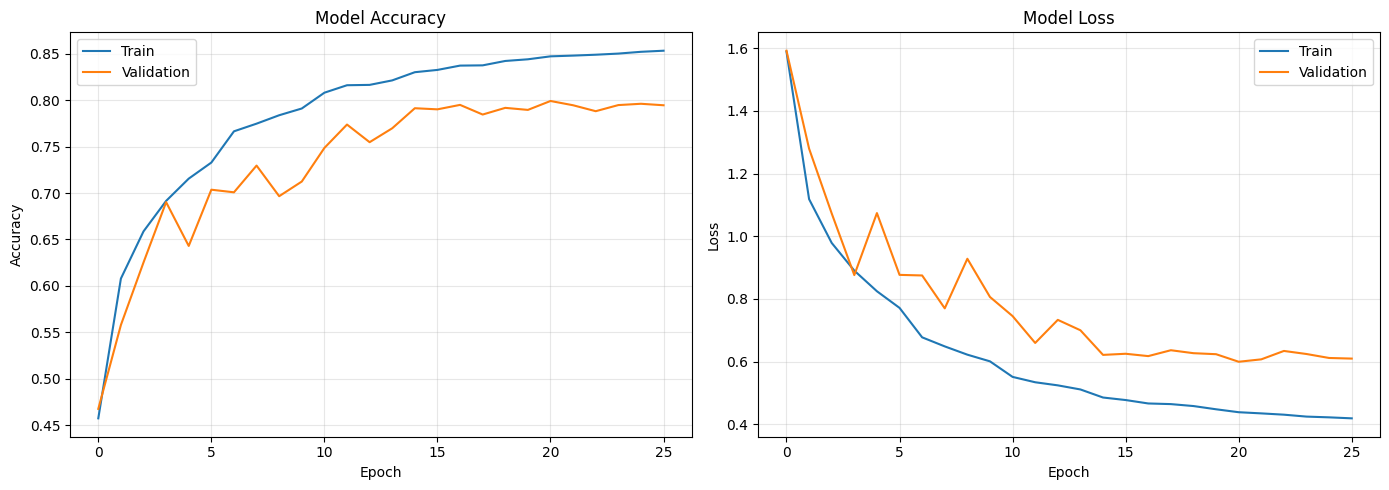

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Evaluation and classification report

In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}\n")

y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Test loss:     0.6370
Test accuracy: 0.7866

              precision    recall  f1-score   support

    airplane     0.8268    0.8020    0.8142      1000
  automobile     0.9108    0.8880    0.8992      1000
        bird     0.6732    0.7250    0.6981      1000
         cat     0.6098    0.6500    0.6292      1000
        deer     0.6965    0.8170    0.7520      1000
         dog     0.7464    0.6710    0.7067      1000
        frog     0.8155    0.8400    0.8276      1000
       horse     0.8981    0.7400    0.8114      1000
        ship     0.8464    0.8930    0.8691      1000
       truck     0.9023    0.8400    0.8700      1000

    accuracy                         0.7866     10000
   macro avg     0.7926    0.7866    0.7878     10000
weighted avg     0.7926    0.7866    0.7878     10000



## 10. Inference on a random test image

Test image index: 7270
Actual label:     truck
Predicted label:  truck (99.91% confidence)
Correct!


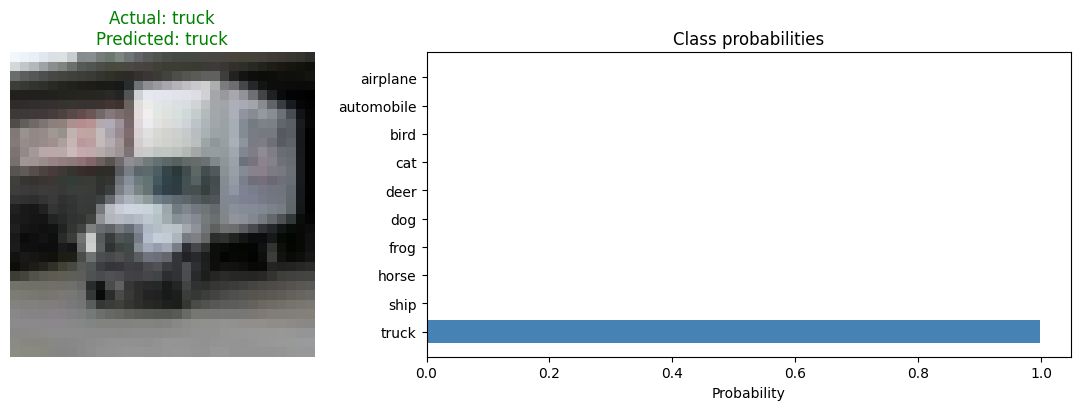

In [12]:
idx = np.random.randint(0, len(x_test))
img = x_test[idx]

probs = model.predict(img[np.newaxis, ...], verbose=0)[0]
pred_label = np.argmax(probs)
actual_label = y_test[idx]

print(f"Test image index: {idx}")
print(f"Actual label:     {class_names[actual_label]}")
print(f"Predicted label:  {class_names[pred_label]} ({probs[pred_label]:.2%} confidence)")
print("Correct!" if pred_label == actual_label else "Wrong prediction.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [1, 2]})

axes[0].imshow(img)
axes[0].set_title(f"Actual: {class_names[actual_label]}\nPredicted: {class_names[pred_label]}",
                  color='green' if pred_label == actual_label else 'red')
axes[0].axis('off')

axes[1].barh(class_names, probs, color='steelblue')
axes[1].set_xlabel("Probability")
axes[1].set_title("Class probabilities")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()